# Remaining useful life prediction on NASA turbofan data (C-MAPSS FD001)

**Goal.** Given the sensor history of a jet engine up to now, predict how many flight cycles it has left before failure (remaining useful life, RUL).

**What this notebook does**

1. Loads and audits the data.
2. Builds RUL labels and a **split by engine**, so no engine appears in both training and validation.
3. Shows how much a random row split would overstate performance.
4. Trains three baselines (constant, ridge, gradient boosting) and a **PyTorch LSTM**.
5. Scores everything on NASA's held-out test engines with RMSE and the asymmetric NASA score, over several seeds.

Runs on CPU in a few minutes. No GPU needed.

## 1. Setup and data

In [1]:
import subprocess, time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

SEED = 42
FD = "FD001"      # one operating condition, one fault mode
RUL_CAP = 125     # see section 3
WINDOW = 30       # cycles of history the models see
VAL_ENGINES = 20  # engines held out for validation

DATA_DIR = Path("CMAPSSData")
if not (DATA_DIR / f"train_{FD}.txt").exists():
    # Mirror of the NASA Prognostics Center of Excellence turbofan files.
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/edwardzjl/CMAPSSData", str(DATA_DIR)], check=True)
print("torch", torch.__version__, "| data:", sorted(p.name for p in DATA_DIR.glob(f"*{FD}.txt")))

torch 2.15.0+cu132 | data: ['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']


Each row is one engine on one flight cycle: an engine id, the cycle number, 3 operating settings and 21 sensor readings.

- **Training file:** every engine runs until it fails.
- **Test file:** every engine is cut off at some point before failure. `RUL_FD001.txt` holds the true number of cycles each one had left.

In [2]:
COLS = ["unit", "cycle"] + [f"setting_{i}" for i in (1, 2, 3)] + [f"s{i}" for i in range(1, 22)]

def load(name):
    return pd.read_csv(DATA_DIR / name, sep=r"\s+", header=None, names=COLS)

train_full = load(f"train_{FD}.txt")
test = load(f"test_{FD}.txt")
rul_test = pd.read_csv(DATA_DIR / f"RUL_{FD}.txt", header=None)[0].to_numpy()

print(f"train: {len(train_full):,} rows, {train_full.unit.nunique()} engines")
print(f"test:  {len(test):,} rows, {test.unit.nunique()} engines, {len(rul_test)} RUL labels")
train_full.head(3)

train: 20,631 rows, 100 engines
test:  13,096 rows, 100 engines, 100 RUL labels


,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


## 2. Data audit

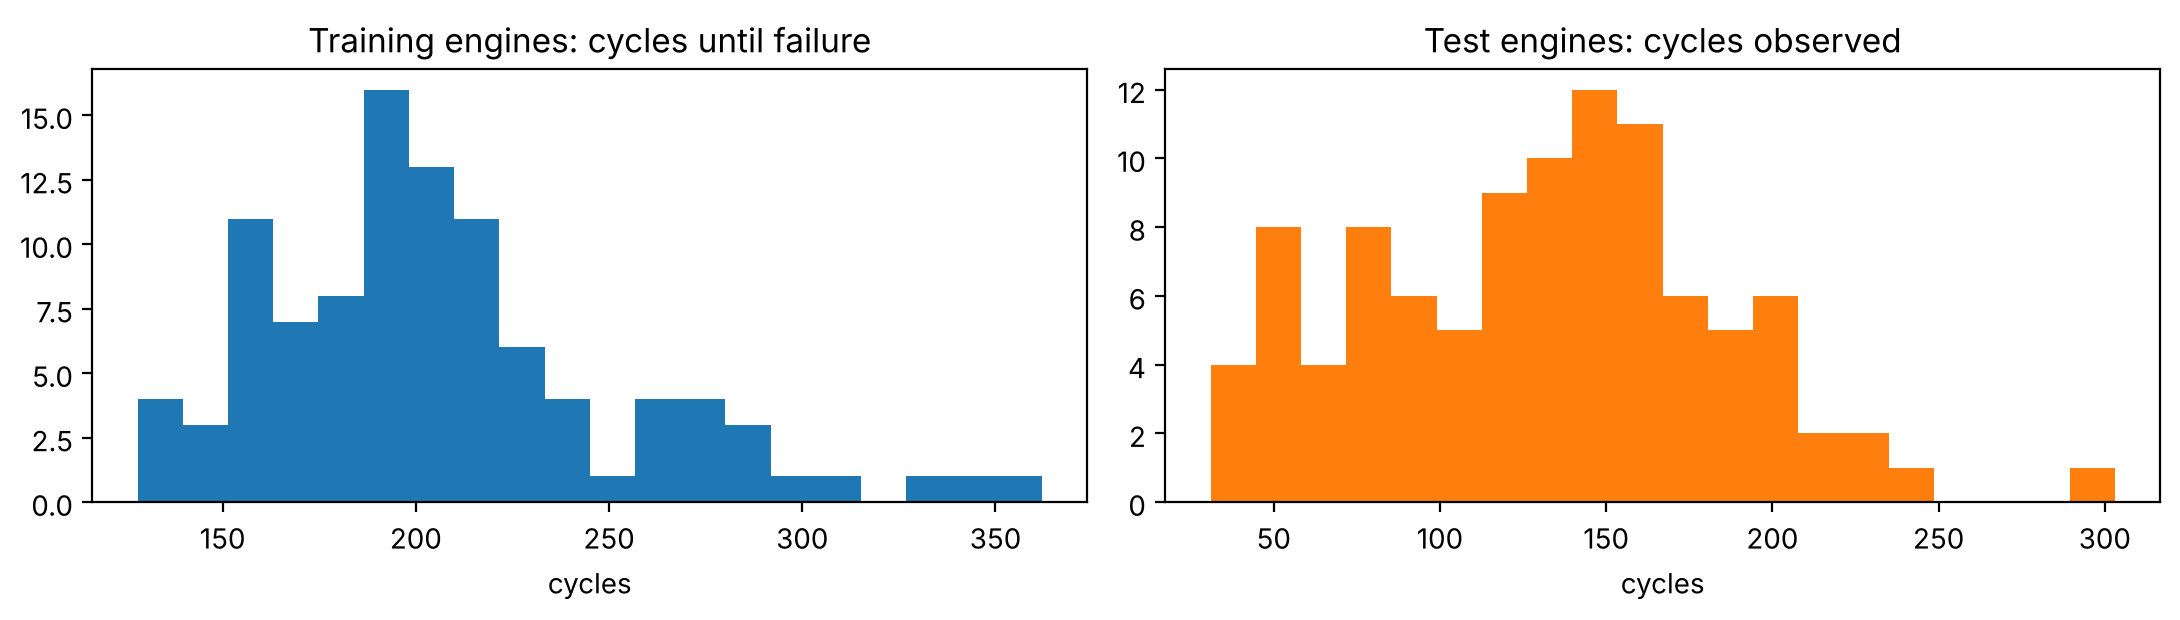

Training lifetimes: 128 to 362 cycles (median 199)
Test histories:     31 to 303 cycles (median 133)
True test RUL:      7 to 145 cycles (median 86)


In [3]:
life = train_full.groupby("unit")["cycle"].max()
seen = test.groupby("unit")["cycle"].max()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(life, bins=20); ax[0].set_title("Training engines: cycles until failure"); ax[0].set_xlabel("cycles")
ax[1].hist(seen, bins=20, color="tab:orange"); ax[1].set_title("Test engines: cycles observed"); ax[1].set_xlabel("cycles")
plt.tight_layout(); plt.show()

print(f"Training lifetimes: {life.min()} to {life.max()} cycles (median {int(life.median())})")
print(f"Test histories:     {seen.min()} to {seen.max()} cycles (median {int(seen.median())})")
print(f"True test RUL:      {rul_test.min()} to {rul_test.max()} cycles (median {int(np.median(rul_test))})")

Several sensors never change in FD001, so they carry no information. The operating settings are also dropped here because FD001 has a single operating condition. (FD002 and FD004 have six conditions, where the settings matter.)

In [4]:
sensors = [f"s{i}" for i in range(1, 22)]
nunique = train_full[sensors].nunique()
FEATURES = [s for s in sensors if nunique[s] > 2]
print("Dropped (constant or two-valued):", [s for s in sensors if s not in FEATURES])
print(f"Kept {len(FEATURES)} sensors:", FEATURES)

Dropped (constant or two-valued): ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
Kept 14 sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


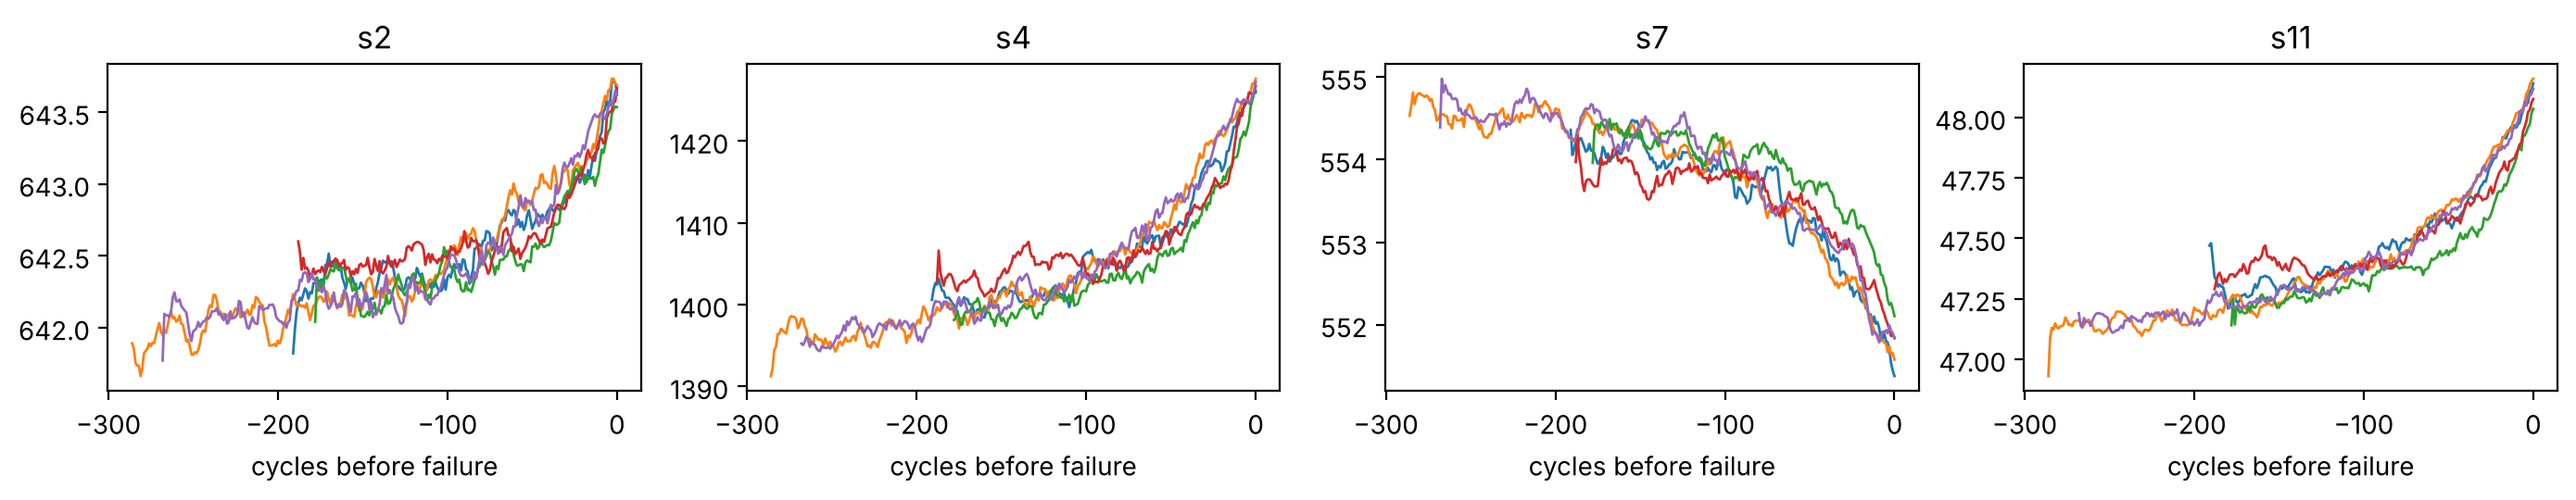

In [5]:
# How four sensors drift as engines approach failure (5 engines, aligned at failure).
tmp = train_full.copy()
tmp["rul"] = tmp.groupby("unit")["cycle"].transform("max") - tmp["cycle"]
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, s in zip(axes, ["s2", "s4", "s7", "s11"]):
    for u in range(1, 6):
        g = tmp[tmp.unit == u]
        ax.plot(-g["rul"], g[s].rolling(10, min_periods=1).mean(), lw=1)
    ax.set_title(s); ax.set_xlabel("cycles before failure")
plt.tight_layout(); plt.show()

## 3. Labels

RUL at a given row is the engine's last cycle minus the current cycle.

Early in an engine's life the sensors look healthy and say nothing about whether failure is 150 or 250 cycles away. The standard fix is to **cap the target at 125 cycles**: the model learns "healthy" as one value and only has to count down once degradation is visible. The sensor plots in section 2 show why: the curves are flat until roughly the last 100 to 150 cycles.

In [6]:
train_full["rul"] = train_full.groupby("unit")["cycle"].transform("max") - train_full["cycle"]
train_full["y"] = train_full["rul"].clip(upper=RUL_CAP)

## 4. Split by engine

Rows from the same engine are highly correlated: cycle 150 and cycle 151 of one engine are nearly identical. A random row split puts those neighbours on both sides, and the model is then tested on engines it has already seen.

So the split is **by engine**: 20 whole engines are held out for validation. The scaler is fitted on the training engines only.

In [7]:
rng = np.random.default_rng(SEED)
units = rng.permutation(train_full["unit"].unique())
val_units = set(units[:VAL_ENGINES])

train = train_full[~train_full.unit.isin(val_units)].copy()
val = train_full[train_full.unit.isin(val_units)].copy()
assert not set(train.unit) & set(val.unit)

scaler = StandardScaler().fit(train[FEATURES])
def scaled(df):
    out = df.copy()
    out[FEATURES] = scaler.transform(out[FEATURES])
    return out

train_s, val_s, test_s = scaled(train), scaled(val), scaled(test)
print(f"train: {train.unit.nunique()} engines, {len(train):,} rows | val: {val.unit.nunique()} engines, {len(val):,} rows")

train: 80 engines, 16,779 rows | val: 20 engines, 3,852 rows


## 5. Metrics and test protocol

For each test engine the model sees its history and predicts RUL **at the last observed cycle**. That gives 100 predictions to compare with NASA's 100 true values.

- **RMSE** in cycles. Reported two ways: against the true RUL, and against the true RUL capped at 125 (many papers report the capped version, so both are shown to keep comparisons honest).
- **NASA score** (Saxena et al., 2008). Predicting too late is penalised more than predicting too early, because a late prediction means the engine fails before maintenance. Lower is better. It is a sum, and it is dominated by the worst few engines.

In [8]:
def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def nasa_score(y, p):
    d = np.asarray(p) - np.asarray(y)          # positive = predicted too late
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

rul_test_capped = np.minimum(rul_test, RUL_CAP)
results = []

def report(name, pred_test, val_rmse=None):
    row = {"model": name,
           "val RMSE (all cycles)": val_rmse,
           "test RMSE (capped truth)": rmse(rul_test_capped, pred_test),
           "test RMSE (true RUL)": rmse(rul_test, pred_test),
           "NASA score": nasa_score(rul_test, pred_test)}
    results.append(row)
    return row

## 6. Baselines

A deep model is only worth having if it beats simple ones.

- **Constant:** always predict the mean training target.
- **Ridge** and **LightGBM** on hand-built features: the current sensor values plus their rolling mean and standard deviation over the last 30 cycles.

In [9]:
def rolling_features(df):
    g = df.groupby("unit")[FEATURES]
    mean = g.rolling(WINDOW, min_periods=1).mean().reset_index(level=0, drop=True).add_suffix("_mean")
    std = g.rolling(WINDOW, min_periods=2).std().reset_index(level=0, drop=True).fillna(0).add_suffix("_std")
    return pd.concat([df[FEATURES], mean, std], axis=1)

X_tr, X_va, X_te = rolling_features(train_s), rolling_features(val_s), rolling_features(test_s)
last_rows = test.groupby("unit")["cycle"].idxmax().to_numpy()   # last observed cycle of each test engine
X_te_last = X_te.loc[last_rows]

const = float(train["y"].mean())
report("Constant (mean)", np.full(len(rul_test), const), rmse(val["y"], np.full(len(val), const)))

ridge = Ridge(alpha=1.0).fit(X_tr, train["y"])
clip = lambda p: np.clip(p, 0, RUL_CAP)
report("Ridge, rolling features", clip(ridge.predict(X_te_last)), rmse(val["y"], clip(ridge.predict(X_va))))

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
gbm = lgb.LGBMRegressor(**LGB_PARAMS).fit(X_tr, train["y"])
report("LightGBM, rolling features", clip(gbm.predict(X_te_last)), rmse(val["y"], clip(gbm.predict(X_va))))
pd.DataFrame(results).round(2)

,model,val RMSE (all cycles),test RMSE (capped truth),test RMSE (true RUL),NASA score
0,Constant (mean),41.96,42.13,43.24,35722.89
1,"Ridge, rolling features",19.78,17.48,18.74,666.04
2,"LightGBM, rolling features",17.00,15.83,17.07,679.78


### What a random row split would have claimed

Same LightGBM, same features, but validated on a random 20% of rows instead of 20% of engines.

In [10]:
X_all = rolling_features(scaled(train_full))
perm = np.random.default_rng(SEED).permutation(len(train_full))
cut = int(0.8 * len(perm))
gbm_leaky = lgb.LGBMRegressor(**LGB_PARAMS).fit(X_all.iloc[perm[:cut]], train_full["y"].iloc[perm[:cut]])
leaky_val = rmse(train_full["y"].iloc[perm[cut:]], clip(gbm_leaky.predict(X_all.iloc[perm[cut:]])))
honest_val = results[-1]["val RMSE (all cycles)"]
print(f"Random row split, validation RMSE: {leaky_val:5.2f} cycles")
print(f"Engine split, validation RMSE:     {honest_val:5.2f} cycles")
print(f"Held-out test engines, RMSE:       {results[-1]['test RMSE (capped truth)']:5.2f} cycles (capped truth)")

Random row split, validation RMSE:  9.75 cycles
Engine split, validation RMSE:     17.00 cycles
Held-out test engines, RMSE:       15.83 cycles (capped truth)


The random split reports an error far below what the model achieves on unseen engines. The engine split lands close to the real test result, which is what a validation set is for.

## 7. PyTorch LSTM

Instead of hand-built rolling statistics, the LSTM reads the raw last 30 cycles of all sensors and learns its own summary.

- Input: a `(30 cycles, 14 sensors)` window. Target: capped RUL at the window's last cycle, divided by 125 so it sits in 0 to 1.
- Early stopping on the validation engines.
- Trained with several seeds, because a single run on 80 engines is noisy.

In [11]:
def pad_front(a):
    # An engine with fewer than WINDOW cycles is padded by repeating its first row.
    if len(a) < WINDOW:
        a = np.vstack([np.repeat(a[:1], WINDOW - len(a), axis=0), a])
    return a

def all_windows(df):
    X, y = [], []
    for _, g in df.groupby("unit"):
        a = pad_front(g[FEATURES].to_numpy(np.float32))
        target = g["y"].to_numpy(np.float32)
        offset = len(a) - len(g)
        for end in range(WINDOW, len(a) + 1):
            X.append(a[end - WINDOW:end]); y.append(target[end - 1 - offset])
    return np.stack(X), np.array(y, np.float32)

def last_windows(df):
    return np.stack([pad_front(g[FEATURES].to_numpy(np.float32))[-WINDOW:] for _, g in df.groupby("unit")])

Xw_tr, yw_tr = all_windows(train_s)
Xw_va, yw_va = all_windows(val_s)
Xw_te = last_windows(test_s)
print("train windows", Xw_tr.shape, "| val windows", Xw_va.shape, "| test windows", Xw_te.shape)

train windows (14459, 30, 14) | val windows (3272, 30, 14) | test windows (100, 30, 14)


In [12]:
class RULNet(nn.Module):
    def __init__(self, n_features, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=2, batch_first=True, dropout=0.2)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)     # use the state after the last cycle

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return (model(torch.as_tensor(X)) * RUL_CAP).clamp(0, RUL_CAP).numpy()

def train_lstm(seed, max_epochs=40, patience=6, batch=256, lr=1e-3):
    torch.manual_seed(seed)
    model = RULNet(len(FEATURES))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    X, y = torch.as_tensor(Xw_tr), torch.as_tensor(yw_tr) / RUL_CAP
    best, best_state, bad, history = np.inf, None, 0, []
    for epoch in range(max_epochs):
        model.train()
        order, total = torch.randperm(len(X)), 0.0
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(X[idx]), y[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(idx)
        val_rmse = rmse(yw_va, predict(model, Xw_va))
        history.append({"epoch": epoch + 1, "train_mse": total / len(X), "val_rmse": val_rmse})
        if val_rmse < best - 1e-3:
            best, bad = val_rmse, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best, pd.DataFrame(history)

In [13]:
SEEDS = [0, 1, 2, 3, 4]
runs = []
for seed in SEEDS:
    t0 = time.time()
    model, best_val, history = train_lstm(seed)
    pred = predict(model, Xw_te)
    runs.append({"seed": seed, "model": model, "history": history, "pred": pred, "val_rmse": best_val,
                 "test_rmse_capped": rmse(rul_test_capped, pred), "test_rmse_true": rmse(rul_test, pred),
                 "nasa": nasa_score(rul_test, pred)})
    print(f"seed {seed}: {len(history):2d} epochs, train MSE {history.train_mse.iloc[0]:.4f} -> {history.train_mse.iloc[-1]:.4f}, "
          f"val RMSE {best_val:.2f}, test RMSE {runs[-1]['test_rmse_capped']:.2f} (capped) / {runs[-1]['test_rmse_true']:.2f} (true), "
          f"NASA score {runs[-1]['nasa']:.0f}  [{time.time() - t0:.0f}s]")

seed 0: 14 epochs, train MSE 0.1731 -> 0.0088, val RMSE 13.70, test RMSE 14.34 (capped) / 15.77 (true), NASA score 368  [23s]


seed 1: 12 epochs, train MSE 0.0921 -> 0.0087, val RMSE 14.31, test RMSE 14.22 (capped) / 15.57 (true), NASA score 393  [20s]


seed 2: 13 epochs, train MSE 0.2132 -> 0.0085, val RMSE 13.83, test RMSE 14.61 (capped) / 16.15 (true), NASA score 474  [20s]


seed 3: 15 epochs, train MSE 0.1873 -> 0.0074, val RMSE 13.76, test RMSE 13.68 (capped) / 14.97 (true), NASA score 367  [24s]


seed 4: 13 epochs, train MSE 0.1348 -> 0.0086, val RMSE 13.67, test RMSE 14.47 (capped) / 15.79 (true), NASA score 401  [20s]


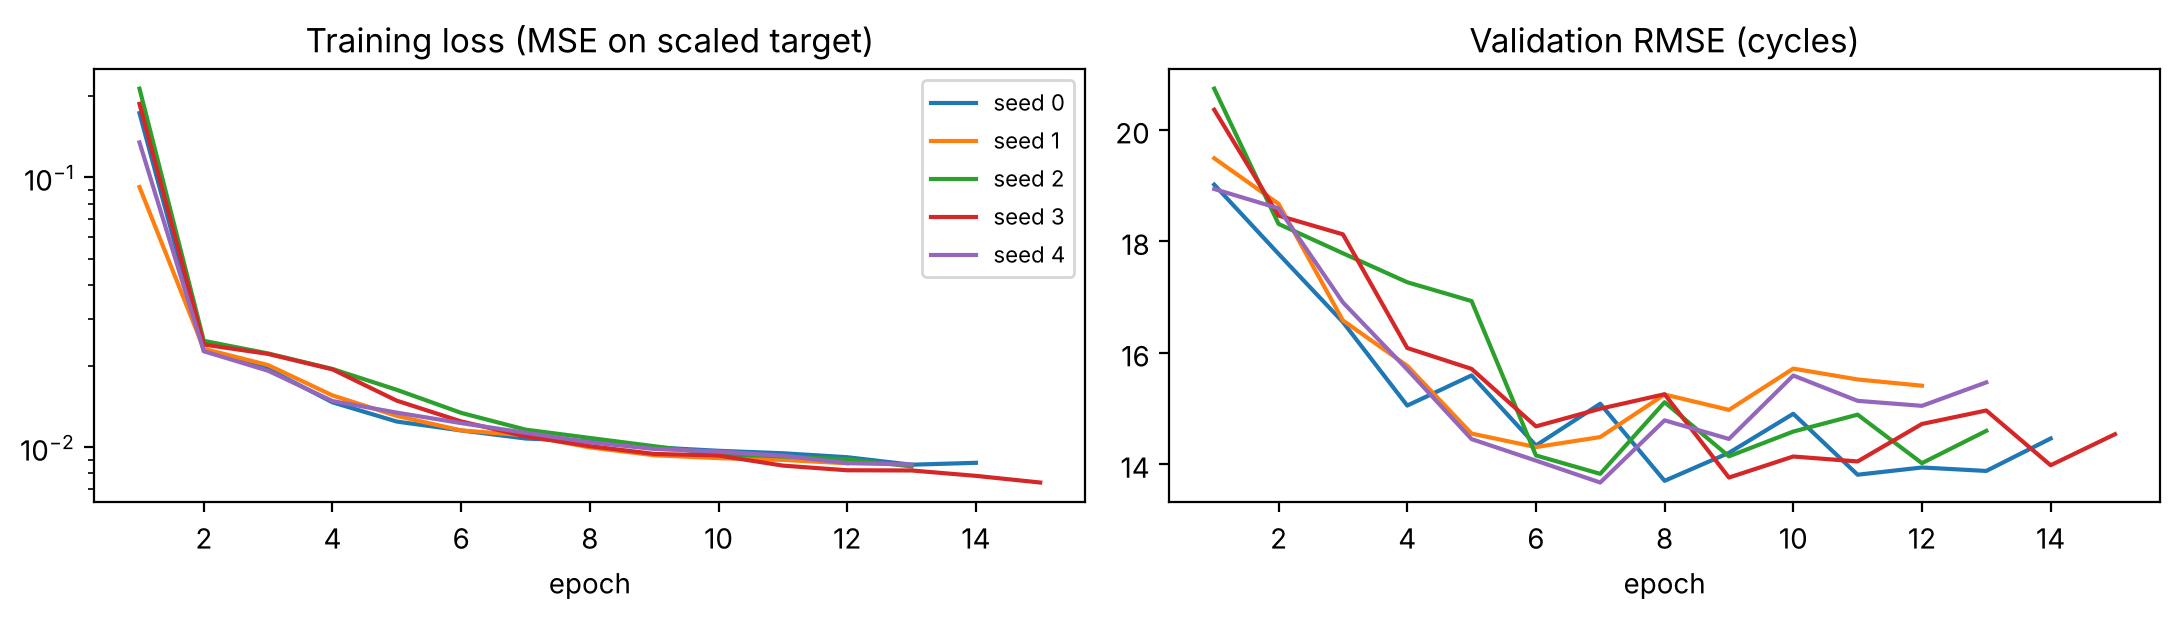

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for r in runs:
    ax[0].plot(r["history"].epoch, r["history"].train_mse, label=f"seed {r['seed']}")
    ax[1].plot(r["history"].epoch, r["history"].val_rmse)
ax[0].set_title("Training loss (MSE on scaled target)"); ax[0].set_xlabel("epoch"); ax[0].set_yscale("log"); ax[0].legend(fontsize=8)
ax[1].set_title("Validation RMSE (cycles)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 8. Results

In [15]:
table = pd.DataFrame(results)
lstm = pd.DataFrame([{k: r[k] for k in ("val_rmse", "test_rmse_capped", "test_rmse_true", "nasa")} for r in runs])
table.loc[len(table)] = ["LSTM (mean of 5 seeds)", lstm.val_rmse.mean(), lstm.test_rmse_capped.mean(),
                         lstm.test_rmse_true.mean(), lstm.nasa.mean()]
ensemble = np.mean([r["pred"] for r in runs], axis=0)
table.loc[len(table)] = ["LSTM (5-seed ensemble)", np.nan, rmse(rul_test_capped, ensemble),
                         rmse(rul_test, ensemble), nasa_score(rul_test, ensemble)]
print(f"LSTM across seeds: test RMSE (capped) {lstm.test_rmse_capped.mean():.2f} +/- {lstm.test_rmse_capped.std():.2f}, "
      f"range {lstm.test_rmse_capped.min():.2f} to {lstm.test_rmse_capped.max():.2f}; "
      f"NASA score {lstm.nasa.mean():.0f} +/- {lstm.nasa.std():.0f}")
table["val RMSE (all cycles)"] = table["val RMSE (all cycles)"].astype(float)
table.round(2)

LSTM across seeds: test RMSE (capped) 14.27 +/- 0.36, range 13.68 to 14.61; NASA score 401 +/- 44


,model,val RMSE (all cycles),test RMSE (capped truth),test RMSE (true RUL),NASA score
0,Constant (mean),41.96,42.13,43.24,35722.89
1,"Ridge, rolling features",19.78,17.48,18.74,666.04
2,"LightGBM, rolling features",17.00,15.83,17.07,679.78
3,LSTM (mean of 5 seeds),13.86,14.27,15.65,400.69
4,LSTM (5-seed ensemble),NaN,13.67,15.11,333.78


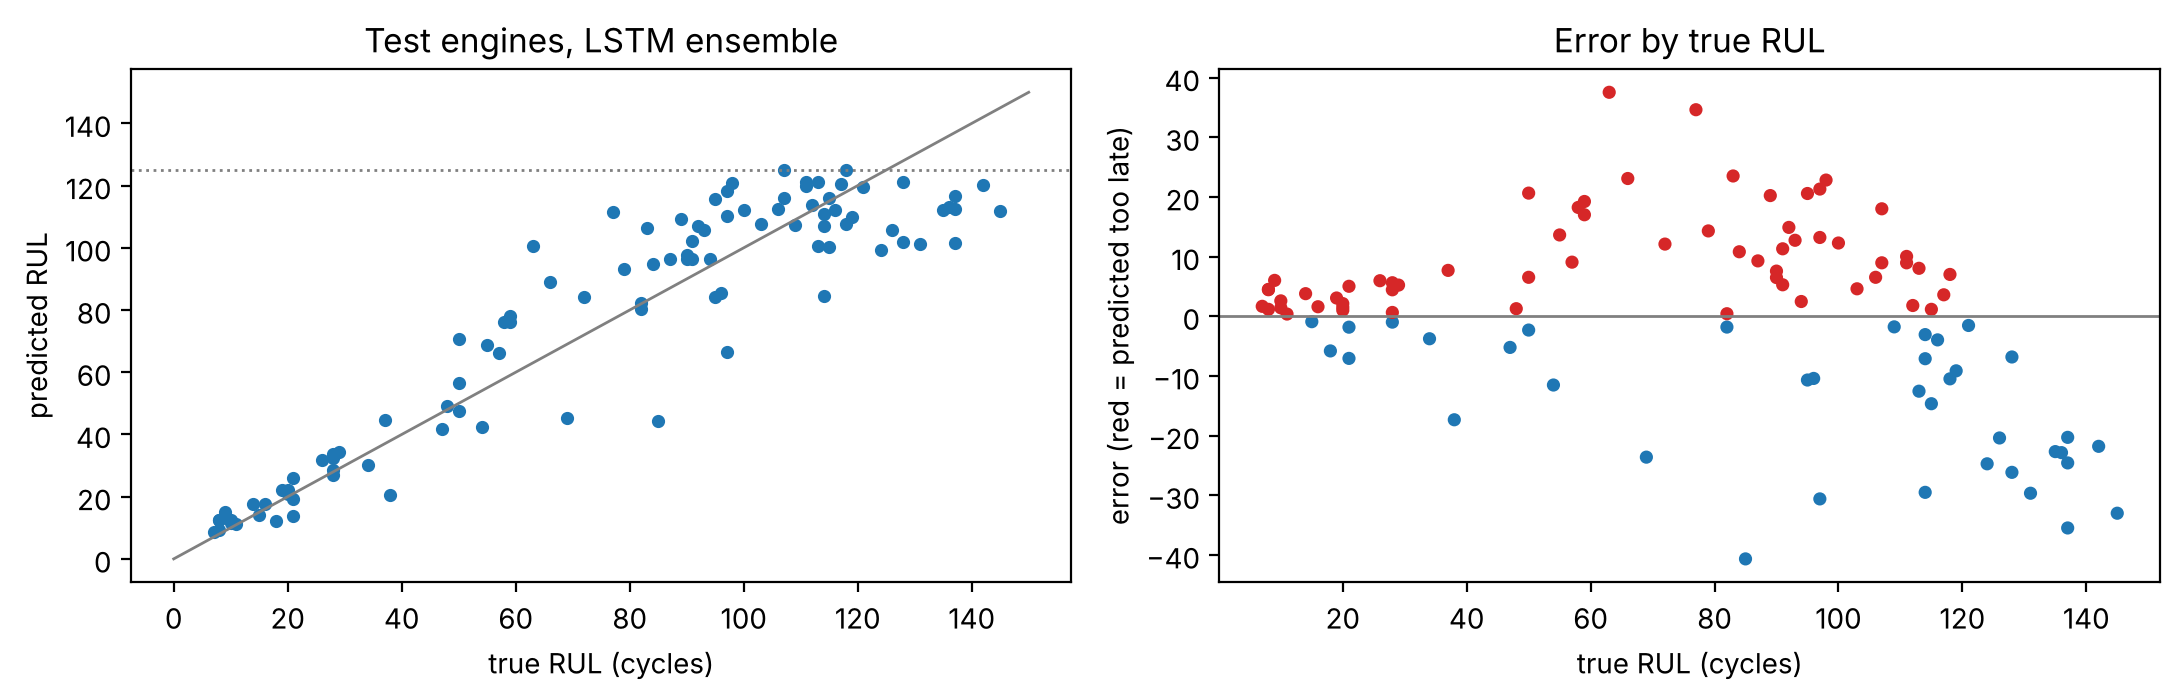

Engines within 50 cycles of failure (33): RMSE 6.10
Engines with 50 to 125 cycles left (56): RMSE 16.20
Five worst engines (unit, true, predicted): [(93, 85, 44), (79, 63, 101), (55, 137, 102), (67, 77, 112), (25, 145, 112)]


In [16]:
err = ensemble - rul_test
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(rul_test, ensemble, s=14)
ax[0].plot([0, 150], [0, 150], color="grey", lw=1); ax[0].axhline(RUL_CAP, color="grey", ls=":", lw=1)
ax[0].set_xlabel("true RUL (cycles)"); ax[0].set_ylabel("predicted RUL"); ax[0].set_title("Test engines, LSTM ensemble")
ax[1].scatter(rul_test, err, s=14, c=np.where(err > 0, "tab:red", "tab:blue"))
ax[1].axhline(0, color="grey", lw=1)
ax[1].set_xlabel("true RUL (cycles)"); ax[1].set_ylabel("error (red = predicted too late)"); ax[1].set_title("Error by true RUL")
plt.tight_layout(); plt.show()

near = rul_test <= 50
print(f"Engines within 50 cycles of failure ({near.sum()}): RMSE {rmse(rul_test[near], ensemble[near]):.2f}")
print(f"Engines with 50 to 125 cycles left ({((rul_test > 50) & (rul_test <= RUL_CAP)).sum()}): "
      f"RMSE {rmse(rul_test[(rul_test > 50) & (rul_test <= RUL_CAP)], ensemble[(rul_test > 50) & (rul_test <= RUL_CAP)]):.2f}")
worst = np.argsort(-np.abs(err))[:5]
print("Five worst engines (unit, true, predicted):", [(int(u + 1), int(rul_test[u]), int(round(ensemble[u]))) for u in worst])

## 9. Limitations

- **Simulated data.** C-MAPSS is a simulator, not field data. Real fleets have missing sensors, maintenance events and changing operating conditions.
- **Easiest subset.** FD001 has one operating condition and one fault mode. FD002 to FD004 are harder and are not covered here.
- **Small test set.** 100 engines, so differences of a cycle or so between models are within seed noise (see the spread across seeds above).
- **The cap is a modelling choice.** Predictions cannot exceed 125 cycles, so the model cannot rank healthy engines against each other.
- **No uncertainty per prediction.** The model gives a point estimate; a maintenance planner would want an interval.

## 10. Next steps

1. Run FD002 to FD004 with per-operating-condition normalisation, and train on one subset and test on another.
2. Track runs with MLflow (parameters, metrics, model artifact).
3. Add an anomaly detector that flags when an engine leaves the healthy regime.
4. Serve the model behind a FastAPI endpoint and package it with Docker.